# RDA prompt versions compared

One sample, several saved prompt versions, three models. For every field the person
annotated, each version's output is **Correct** (same value), a **Mismatch** (a
different value) or **Missed** (nothing written there) - the same labels as the field
matrix. Lower mismatch and missed are better; a mismatch is the costlier error, since
it is a wrong value that looks right.

**To compare other versions or another sample:** change `RUNS` and `SAMPLE` in the next cell.


In [1]:
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

if Path.cwd().name == "notebooks":
    import os
    os.chdir(Path.cwd().parent)

from dmpbridge.rda import evaluate as E

SAMPLE = 3
# (label shown in the figure, folder under notebooks/rda-experiments/runs/)
RUNS = [("v9",                "v9-sample3"),
        ("v10",               "v10-sample3"),
        ("v11",               "v11-sample3"),
        ("v12",               "v12-sample3")]
MODELS = ["llama3.1-8b", "gemma4-e4b", "llama3.3-70b"]
NAME   = {"llama3.1-8b": "Llama 3.1 8B", "gemma4-e4b": "Gemma 4 e4b", "llama3.3-70b": "Llama 3.3 70B"}
OUTCOMES = ["Correct", "Mismatch", "Missed"]
COLOUR = {"Correct": "#238b45", "Mismatch": "#e34948", "Missed": "#898781"}
OUT_DIR = Path("notebooks/rda-experiments")

INK, MUTED, SURFACE = "#0b0b0b", "#52514e", "#fcfcfb"
plt.rcParams.update({"figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "text.color": INK,
                     "axes.edgecolor": "#d8d8d4", "legend.frameon": False})
pd.set_option("display.width", 200)


## 1. Score every version


In [2]:
ref = E.reference_path(SAMPLE)
rows = []
for label, run in RUNS:
    for m in MODELS:
        f = Path("notebooks/rda-experiments/runs") / run / f"sample{SAMPLE}.rda.{m}.json"
        if not f.exists():
            print(f"{run}: no {m} output for sample {SAMPLE} - left out")
            continue
        _, met, outcomes = E.evaluate_file(f, ref)
        c = Counter(outcomes.values())
        rows.append({"version": label.replace("\n", " "), "model": m, "run": run,
                     **{o: c[o] for o in OUTCOMES}, "F1": met["f1"],
                     "fields written": met["fields output"],
                     "not in reference": met["hallucinated"] - c["Mismatch"]})
        for field, o in outcomes.items():
            rows[-1].setdefault("_parts", []).append((E.row_of(field)[1], o))

df = pd.DataFrame([{k: v for k, v in r.items() if k != "_parts"} for r in rows])
n_fields = len(outcomes)
versions = [v for v in dict.fromkeys(df["version"])]
print(f"sample {SAMPLE}: {n_fields} annotated fields, {len(versions)} versions, {df['model'].nunique()} models")

totals = (df.groupby("version")[OUTCOMES].sum().reindex(versions))
totals["F1 (mean of models)"] = df.groupby("version")["F1"].mean().reindex(versions).round(3)
display(totals)


sample 3: 25 annotated fields, 4 versions, 3 models


,Correct,Mismatch,Missed,F1 (mean of models)
version,,,,
v9,32,5,38,0.529
v10,41,2,32,0.540
v11,31,2,42,0.491
v12,43,3,29,0.528


## 2. The figure: each version, per model and in total

Stacked bars - green correct, red mismatch, grey missed - add up to the annotated
fields (per model) or three times that (total). Saved next to the runs as
`version_comparison_sample{SAMPLE}.png`.


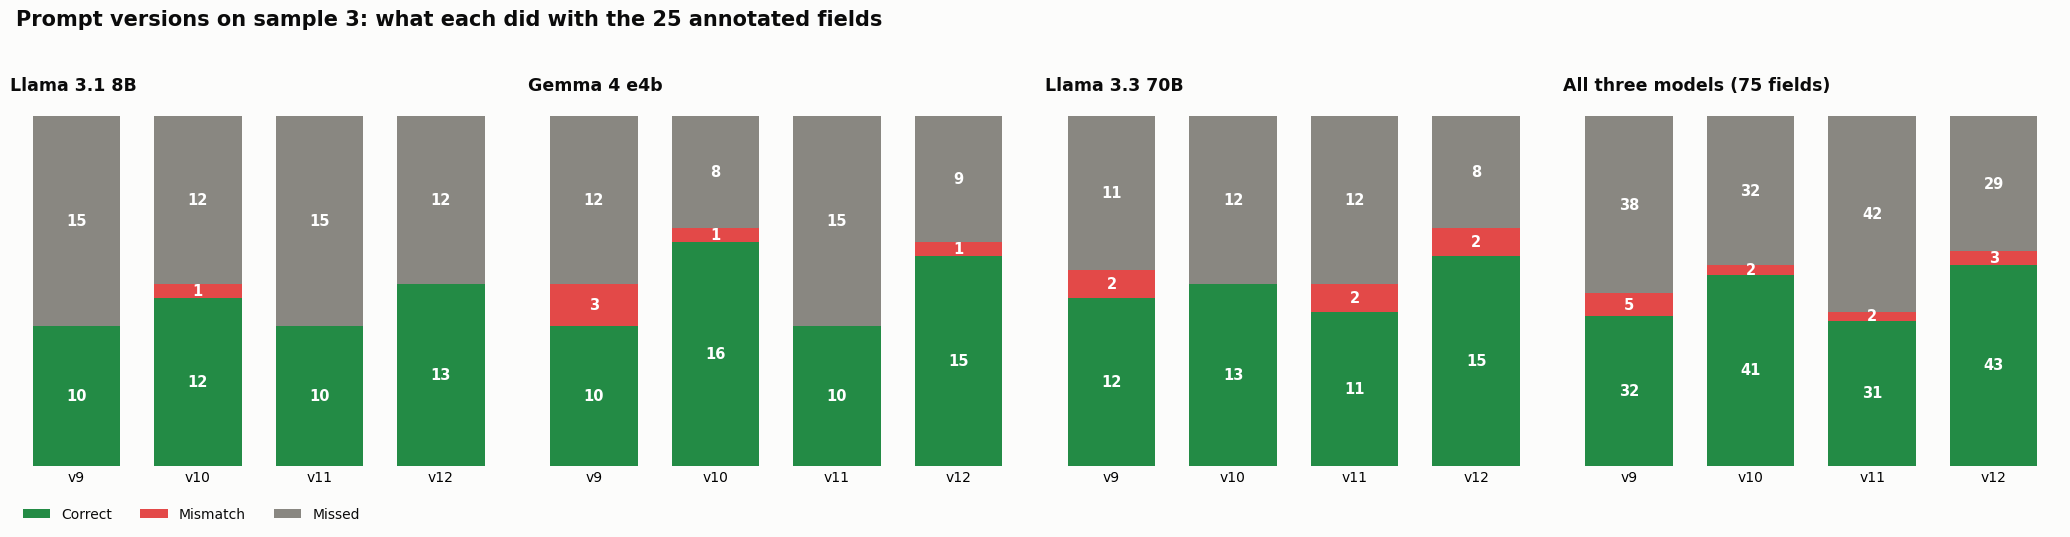

saved -> notebooks\rda-experiments\version_comparison_sample3.png


In [3]:
panels = [(m, df[df["model"] == m].set_index("version").reindex(versions)) for m in MODELS]
panels.append(("total", totals))

fig, axes = plt.subplots(1, len(panels), figsize=(5.2 * len(panels), 5.6), sharey=False)
for ax, (name, d) in zip(axes, panels):
    bottom = np.zeros(len(d))
    for o in OUTCOMES:
        vals = d[o].fillna(0).to_numpy()
        ax.bar(range(len(d)), vals, bottom=bottom, color=COLOUR[o], width=0.72, label=o)
        for i, (v, b) in enumerate(zip(vals, bottom)):
            if v:
                ax.text(i, b + v / 2, f"{int(v)}", ha="center", va="center", fontsize=10.5,
                        color="white" if o != "Missed" or v > 3 else INK, fontweight="bold")
        bottom += vals
    ax.set_xticks(range(len(d)))
    ax.set_xticklabels([l for l, _ in RUNS if l.replace("\n", " ") in d.index], fontsize=10)
    ax.set_title(NAME.get(name, f"All three models ({3 * n_fields} fields)"), fontsize=12.5,
                 fontweight="bold", loc="left")
    ax.tick_params(length=0)
    for s in ax.spines.values():
        s.set_visible(False)
    ax.set_yticks([])
axes[0].legend(loc="upper left", bbox_to_anchor=(0, -0.08), ncol=3, fontsize=10)
fig.suptitle(f"Prompt versions on sample {SAMPLE}: what each did with the {n_fields} annotated fields",
             x=0.01, ha="left", fontsize=15, fontweight="bold")
fig.tight_layout(rect=(0, 0.02, 1, 0.95))
out = OUT_DIR / f"version_comparison_sample{SAMPLE}.png"
fig.savefig(out, dpi=170, bbox_inches="tight", facecolor=SURFACE)
plt.show()
print(f"saved -> {out}")


## 3. Per model

Correct / mismatch / missed and F1 for every version and model. F1 is scored over
every field either side wrote, so it also penalises fields the reference does not
have ("not in reference").


In [4]:
wide = df.pivot(index="version", columns="model", values=OUTCOMES + ["F1"]).reindex(versions)
wide = wide.reorder_levels([1, 0], axis=1).sort_index(axis=1, level=0, sort_remaining=False)
wide = wide[[(m, c) for m in MODELS for c in OUTCOMES + ["F1"] if (m, c) in wide.columns]]
display(wide)
display(df.pivot(index="version", columns="model", values="not in reference").reindex(versions)
          .rename_axis(columns="fields written that the reference does not have"))


model   llama3.1-8b                        gemma4-e4b                        llama3.3-70b                       
            Correct Mismatch Missed     F1    Correct Mismatch Missed     F1      Correct Mismatch Missed     F1
version                                                                                                         
v9             10.0      0.0   15.0  0.511       10.0      3.0   12.0  0.488         12.0      2.0   11.0  0.589
v10            12.0      1.0   12.0  0.495       16.0      1.0    8.0  0.596         13.0      0.0   12.0  0.528
v11            10.0      0.0   15.0  0.524       10.0      0.0   15.0  0.463         11.0      2.0   12.0  0.486
v12            13.0      0.0   12.0  0.514       15.0      1.0    9.0  0.545         15.0      2.0    8.0  0.526

fields written that the reference does not have,gemma4-e4b,llama3.1-8b,llama3.3-70b
version,,,
v9,9,10,7
v10,26,20,19
v11,14,7,14
v12,27,29,39


## 4. By part of the form, summed over the three models

Which parts of the form each version gets right. Each cell: correct / mismatch / missed
out of the annotated fields in that part (times three models).


In [5]:
parts = Counter(p for r in rows if r["version"] == versions[0] for p, _ in r["_parts"])
order = [p[1] for p in E.ROWS if p[1] in parts]
table = {}
for v in versions:
    c = Counter((p, o) for r in rows if r["version"] == v for p, o in r["_parts"])
    table[v] = [f"{c[(p, 'Correct')]} / {c[(p, 'Mismatch')]} / {c[(p, 'Missed')]}" for p in order]
part_df = pd.DataFrame(table, index=[f"{p}  ({parts[p]})" for p in order])
part_df.index.name = "part of the form (annotated fields x 3 models)"
display(part_df)


,v9,v10,v11,v12
part of the form (annotated fields x 3 models),,,,
Plan title & description (6),3 / 1 / 2,3 / 0 / 3,3 / 0 / 3,3 / 0 / 3
Dataset title (12),7 / 2 / 3,10 / 1 / 1,8 / 2 / 2,8 / 1 / 3
Dataset description (12),4 / 2 / 6,2 / 1 / 9,0 / 0 / 12,4 / 2 / 6
Personal & sensitive data (24),18 / 0 / 6,22 / 0 / 2,20 / 0 / 4,18 / 0 / 6
Storage place (host) (3),0 / 0 / 3,1 / 0 / 2,0 / 0 / 3,3 / 0 / 0
Licence (3),0 / 0 / 3,1 / 0 / 2,0 / 0 / 3,1 / 0 / 2
Metadata & standards (15),0 / 0 / 15,2 / 0 / 13,0 / 0 / 15,6 / 0 / 9
